[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eirasf/GCED-AA2/blob/main/es/lab6/lab6-parte1.ipynb)
# Práctica 6: Redes neuronales convolucionales - Parte 1 - FF vs CNN


### Pre-requisitos. Instalar paquetes

Para la primera parte de este Laboratorio 6 necesitaremos, además de torch, el módulo torchvision para cargar los datos. Además, como habitualmente, fijaremos la semilla aleatoria para asegurar la reproducibilidad de los experimentos.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import torchvision
from torchvision import transforms
import os
import numpy as np
import random
from matplotlib import pyplot as plt

# Fijamos la semilla para reproducibilidad
seed = 1234567
os.environ['PYTHONHASHSEED'] = str(seed)
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)


### Carga del conjunto de datos

En esta ocasión trabajaremos con el conjunto de imágenes *mnist*, que representa dígitos escritos a mano. Debemos indicar a nuestro dataloader que haga lotes de 128 elementos.

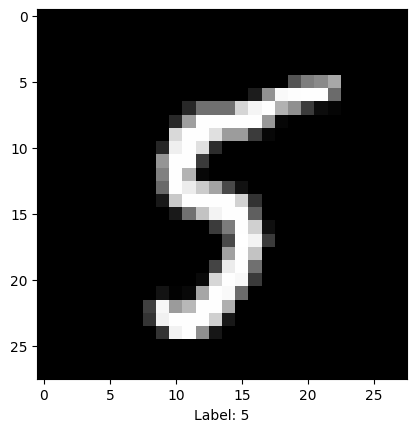

In [2]:
# Cargamos MNIST usando torchvision
transform = transforms.Compose([
    transforms.ToTensor(), # convierte a tensor y escala a [0,1]
])

train_val = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Dividimos train_val en train y val (80/20) usando el generador vinculado a la semilla
train_size = int(0.8 * len(train_val))
val_size = len(train_val) - train_size
generator = torch.Generator().manual_seed(seed)
train_set, val_set = data.random_split(train_val, [train_size, val_size], generator=generator)

# Creamos los DataLoaders
batch_size = 128
train_loader = data.DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = data.DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = data.DataLoader(test_set, batch_size=batch_size, shuffle=False)

NUM_CLASSES = 10
IMAGE_SHAPE = (1, 28, 28)

# Para comprobar que se ha cargado tomamos un elemento y lo mostramos
im_batch, label_batch = next(iter(train_loader))
ej_imagen = im_batch[0]
plt.imshow(ej_imagen.squeeze(), cmap='gray')
plt.xlabel(f'Label: {label_batch[0].item()}')
plt.show()

## Ajustando los datos con un red neuronal feed-forward

Vamos a modelar los datos con una red feed-forward que tenga capas de 40, 25 y 16 unidades (todas con activación ReLU). Debemos tener en cuenta que las imágenes son tensores de dimensión 3 (su `shape` es (1,28,28)), mientras que la entrada de nuestras capas Dense debe ser un tensor de dimensión 1. Para adecuar la entrada a lo que necesitamos, vamos a "aplanar" los tensores de las imágenes, que pasarán de `shape` (28,28,1) a `shape` (784). Para ello aplanaremos el lote de (128,1,28,28) a (128, 784) en la función `forward`.

Por último, la salida de nuestro modelo debe tener tantas componentes como clases distintas tiene el conjunto. Como queremos que la salida aproxime la probabilidad de las distintas clases, lo habitual sería poner una función de activación *softmax*, pero en este caso, por razones de eficiencia del entrenamiento, es mejor dejar una salida lineal y posteriormente usar la función de pérdida `nn.CrossEntropyLoss` que espera las salidas vienen en ese formato.

In [3]:
class MLP(nn.Module):
    # TODO - Completa la clase siguiendo las instrucciones dadas en la celda anterior.
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 40),
            nn.ReLU(),
            nn.Linear(40, 25),
            nn.ReLU(),
            nn.Linear(25, 16),
            nn.ReLU(),
            nn.Linear(16, NUM_CLASSES)  # Salida lineal (logits) para nn.CrossEntropyLoss
        )

    def forward(self, x):
        # Aplanamos el lote de (128, 1, 28, 28) a (128, 784)
        x = self.flatten(x)
        return self.net(x)

### Entrenamiento del modelo
Vamos a establecer la función de pérdida, el optimizador (Adam con el LR por defecto) y la métrica que nos servirá para evaluar el rendimiento del modelo entrenado (precisión categórica).

Como intentamos predecir una clase entre varias, nuestra función de pérdida debe ser la [entropía cruzada](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html). Le indicaremos que la salida de nuestra red como *logits* y las etiquetas con el valor numérico de la clase (no en one-hot encoding).

In [6]:
# Evaluación sobre el conjunto de test
def evaluate(model, dataloader, loss_fn):
    # TODO - Completa la función para que devuelva la pérdida y la tasa de acierto
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    device = next(model.parameters()).device

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    accuracy = correct / total
    return epoch_loss, accuracy


def train_model(model, train_loader, val_loader, loss_fn, optimizer, num_epochs=16):
    # TODO - Completa la función para que haga el entrenamiento devuelva el histórico de pérdidas y tasas de acierto
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / total
        epoch_train_acc = correct / total

        epoch_val_loss, epoch_val_acc = evaluate(model, val_loader, loss_fn)

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)
        train_accs.append(epoch_train_acc)
        val_accs.append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

    return train_losses, val_losses

# TODO - Define el modelo, función de pérdida y optimizador (Adam con lr=0.001) y haz el entrenamiento durante 16 epochs
ff_model = MLP()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(ff_model.parameters(), lr=0.001)
train_losses, val_losses = train_model(ff_model, train_loader, val_loader, loss_fn, optimizer, num_epochs=16)

Epoch 1/16 - Train Loss: 0.7860, Train Acc: 0.7572 | Val Loss: 0.3820, Val Acc: 0.8935
Epoch 2/16 - Train Loss: 0.3130, Train Acc: 0.9119 | Val Loss: 0.2776, Val Acc: 0.9215
Epoch 3/16 - Train Loss: 0.2386, Train Acc: 0.9323 | Val Loss: 0.2243, Val Acc: 0.9350
Epoch 4/16 - Train Loss: 0.1981, Train Acc: 0.9432 | Val Loss: 0.1929, Val Acc: 0.9442
Epoch 5/16 - Train Loss: 0.1666, Train Acc: 0.9530 | Val Loss: 0.1759, Val Acc: 0.9497
Epoch 6/16 - Train Loss: 0.1451, Train Acc: 0.9587 | Val Loss: 0.1611, Val Acc: 0.9523
Epoch 7/16 - Train Loss: 0.1301, Train Acc: 0.9617 | Val Loss: 0.1553, Val Acc: 0.9530
Epoch 8/16 - Train Loss: 0.1176, Train Acc: 0.9654 | Val Loss: 0.1522, Val Acc: 0.9543
Epoch 9/16 - Train Loss: 0.1055, Train Acc: 0.9680 | Val Loss: 0.1413, Val Acc: 0.9575
Epoch 10/16 - Train Loss: 0.0969, Train Acc: 0.9710 | Val Loss: 0.1475, Val Acc: 0.9572
Epoch 11/16 - Train Loss: 0.0874, Train Acc: 0.9737 | Val Loss: 0.1412, Val Acc: 0.9588
Epoch 12/16 - Train Loss: 0.0822, Train A

### Verificación del rendimiento
Aprovecharemos el conjunto de test para comprobar la capacidad de generalización de nuestro modelo. Puedes también visualizar la curva de entrenamiento para identificar potenciales problemas con el entrenamiento.

Resultados en el conjunto de Test:
  - Pérdida (Loss): 0.1187
  - Precisión (Accuracy): 96.78%


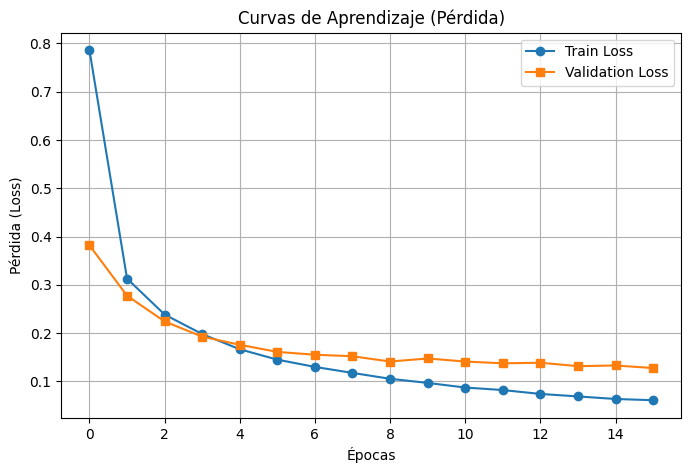

In [7]:
# TODO - Evalúa sobre el conjunto de test
import matplotlib.pyplot as plt

# --- 1. Evaluación sobre el conjunto de test ---
test_loss, test_accuracy = evaluate(ff_model, test_loader, loss_fn)

print("Resultados en el conjunto de Test:")
print(f"  - Pérdida (Loss): {test_loss:.4f}")
print(f"  - Precisión (Accuracy): {test_accuracy * 100:.2f}%")

# --- 2. Visualización de las curvas de entrenamiento y validación ---
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='s')
plt.title('Curvas de Aprendizaje (Pérdida)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

Si todo ha ido correctamente deberías haber obtenido un valor de precisión sobre el conjunto de test comparable a los obtenidos con los conjuntos de entrenamiento y validación, lo que indica que el modelo generaliza bien a otros datos del conjunto original pero... ¿tenemos un buen modelo?

Vamos a comprobar la robustez del modelo haciendo pequeños desplazamientos de las imágenes originales. Utilizaremos un pequeño modelo que aplique una traslación aleatoria de hasta un 10% del tamaño de la imagen a cada una de las imágenes de test. Nos ayudaremos del módulo `transforms` incluido en `torchvision` y en particular de [`transforms.RandomAffine`](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.RandomAffine.html) para hacer traslacciones de hasta un 10% del tamaño de imagen en cualquier dirección.

In [8]:
# Data augmentation: aplicamos una pequeña traslación usando torchvision.transforms
transform_translated = transforms.Compose([
    # Utiliza RandomAffine para hacer traslacciones de hasta un 10% en cualquier dirección (sin rotación)
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
])

# Creamos un dataset de test transformado
test_translated = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform_translated)
test_translated_loader = data.DataLoader(test_translated, batch_size=128, shuffle=False)

Comprobemos ahora la precisión sobre este nuevo conjunto de imágenes que han sido ligeramente desplazadas.

In [9]:
# Evaluamos sobre el conjunto de test desplazado
translated_loss, translated_accuracy = evaluate(ff_model, test_translated_loader, loss_fn)

print("Resultados en el conjunto de Test Desplazado:")
print(f"  - Pérdida (Loss): {translated_loss:.4f}")
print(f"  - Precisión (Accuracy): {translated_accuracy * 100:.2f}%")

Resultados en el conjunto de Test Desplazado:
  - Pérdida (Loss): 1.6897
  - Precisión (Accuracy): 70.54%


Si todo ha ido bien, deberías haber comprobado que estas pequeñas traslaciones son suficientes para que la precisión del modelo baje sustancialmente. Las redes feed-forward no son robustas ante este tipo de perturbaciones.

## Comparativa con una red convolucional

Declara ahora un modelo convolucional con la siguiente arquitectura:
 1. [Convolución 2D](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) de 8 filtros y tamaño de kernel 3, con activación ReLU
 1. [Pooling 2D](https://docs.pytorch.org/docs/2.8/generated/torch.nn.MaxPool2d.html) tomando el máximo de cada grupo de 2x2
  1. [Convolución 2D](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) de 8 filtros y tamaño de kernel 3, con activación ReLU
 1. [Pooling 2D](https://docs.pytorch.org/docs/2.8/generated/torch.nn.MaxPool2d.html) tomando el máximo de cada grupo de 2x2
 1. Capa Densa (requiere aplanado previo) de 32 unidades y activación ReLU
 1. Capa de salida

Define el nuevo modelo, entrénalo y haz las verificaciones posteriores para observar la diferencia.

In [10]:
class ConvModel(nn.Module):
    def __init__(self):
        super(ConvModel, self).__init__()
        # 1. Convolución 2D (8 filtros, kernel 3) + ReLU + Pooling 2x2
        # 2. Convolución 2D (8 filtros, kernel 3) + ReLU + Pooling 2x2
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=8, out_channels=8, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # 3. Aplanado + Capa Densa (32 unidades) + ReLU + Capa de salida
        # Nota: Después de (1, 28, 28), las dimensiones espaciales se reducen a (8, 5, 5), dando 200 características planas.
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(8 * 5 * 5, 32),
            nn.ReLU(),
            nn.Linear(32, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# --- Definición del modelo, función de pérdida y optimizador ---
conv_model = ConvModel()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(conv_model.parameters(), lr=0.001)

# Entrenamiento durante 16 épocas
print("Entrenando la red convolucional (ConvModel)...")
train_losses, val_losses = train_model(
    conv_model, train_loader, val_loader, loss_fn, optimizer, num_epochs=16
)

# --- Verificaciones posteriores ---
print("\n--- Evaluaciones del Modelo Convolucional ---")

# 1. Evaluación sobre el conjunto de test estándar
test_loss_conv, test_accuracy_conv = evaluate(conv_model, test_loader, loss_fn)
print(f"Test Estándar -> Pérdida: {test_loss_conv:.4f} | Precisión: {test_accuracy_conv * 100:.2f}%")

# 2. Evaluación sobre el conjunto de test desplazado (Data Augmentation)
translated_loss_conv, translated_accuracy_conv = evaluate(conv_model, test_translated_loader, loss_fn)
print(f"Test Desplazado -> Pérdida: {translated_loss_conv:.4f} | Precisión: {translated_accuracy_conv * 100:.2f}%")

Entrenando la red convolucional (ConvModel)...
Epoch 1/16 - Train Loss: 0.6732, Train Acc: 0.7931 | Val Loss: 0.2649, Val Acc: 0.9210
Epoch 2/16 - Train Loss: 0.2087, Train Acc: 0.9376 | Val Loss: 0.1679, Val Acc: 0.9492
Epoch 3/16 - Train Loss: 0.1502, Train Acc: 0.9541 | Val Loss: 0.1354, Val Acc: 0.9583
Epoch 4/16 - Train Loss: 0.1260, Train Acc: 0.9616 | Val Loss: 0.1193, Val Acc: 0.9644
Epoch 5/16 - Train Loss: 0.1100, Train Acc: 0.9661 | Val Loss: 0.1117, Val Acc: 0.9655
Epoch 6/16 - Train Loss: 0.0987, Train Acc: 0.9696 | Val Loss: 0.1196, Val Acc: 0.9616
Epoch 7/16 - Train Loss: 0.0902, Train Acc: 0.9721 | Val Loss: 0.0873, Val Acc: 0.9729
Epoch 8/16 - Train Loss: 0.0827, Train Acc: 0.9741 | Val Loss: 0.0848, Val Acc: 0.9741
Epoch 9/16 - Train Loss: 0.0766, Train Acc: 0.9762 | Val Loss: 0.0850, Val Acc: 0.9738
Epoch 10/16 - Train Loss: 0.0697, Train Acc: 0.9792 | Val Loss: 0.0761, Val Acc: 0.9763
Epoch 11/16 - Train Loss: 0.0649, Train Acc: 0.9792 | Val Loss: 0.0740, Val Acc: 0

### Reflexiones sobre la comparativa
 - ¿Qué has observado en el rendimiento?
      * Alta precisión y rapidez de convergencia: El modelo aprende muy rápido. Ya en la primera época supera el $79\%$ de precisión en entrenamiento y el $92\%$ en validación.
      * Estabilidad: Al finalizar las 16 épocas, la precisión en el conjunto de test estándar alcanza un excelente $98.34\%$, con pérdidas muy bajas y estables, lo que demuestra que la red extrae características visuales espaciales muy eficaces para clasificar los dígitos de MNIST.

 - ¿Cuántos parámetros tiene la red convolucional respecto a la *feed-forward*
      * Menor número de parámetros: A pesar de ser una red más compleja en cuanto a su capacidad de procesamiento espacial, la red convolucional suele tener menos parámetros totales que la red feed-forward anterior.
      * Por qué ocurre: En una capa densa (MLP), cada neurona está conectada a todos los píxeles de la entrada (por ejemplo, $784 \times 40$ solo en la primera capa). En cambio, las capas convolucionales comparten pesos utilizando filtros pequeños (kernels de $3 \times 3$), lo que reduce drásticamente el número de parámetros necesarios sin perder capacidad expresiva.

 - ¿Cómo ha cambiado el tiempo de ejecución?
      * Tiempo por época muy similar: Aunque las operaciones convolucionales y de pooling realizan cálculos matriciales específicos, al tener un número de parámetros global moderado, el tiempo de entrenamiento por época sigue siendo muy rápido (pocos segundos en CPU/GPU para MNIST). No se aprecia una ralentización drástica respecto al MLP.

 - ¿Es más robusta frente a los desplazamientos esta red?
      * Sí, notablemente más robusta
      * Mientras que una red feed-forward pura sufre una caída drástica de rendimiento ante pequeñas traslaciones (porque depende de la posición exacta de cada píxel en la entrada), el modelo convolucional mantiene una precisión del $85.10\%$ en el conjunto de test desplazado.
      * Las capas de convolución y max pooling proporcionan una propiedad fundamental llamada invarianza espacial parcial: la red aprende a reconocer la forma del dígito (como los bordes y curvas) independientemente de si está ligeramente desplazado hacia un lado, arriba o abajo.